# Tutorial 2 — faststack, the robust stack of the samples

**faststack (Harrison 2011, Exp. Astron. 31, 1) makes a picture of the sky
from the windows without a filter, without an inversion and without a
model of the line-spread function: every sky pixel collects, from each
window, the one sample whose strip covers it, and takes a robust average
that ignores the samples the primary's light fell into.** This page builds
the stack step by step on a well-sampled campaign, writes Harrison's four
equations out for one pixel and checks them against `scanlib.radon.faststack`,
and then shows where the picture breaks.

**What you will see.**

1. The footprint of a sample on the sky: a strip one pitch wide, as long as
   the window is wide across the scan.
2. The plain mean of the collected samples, and why it smears the primary
   along every scan line through a pixel.
3. The sorted samples of one pixel, the reference level r₀ of the lowest few,
   and the weight that suppresses the rest (Eqs. 1–4).
4. The faststack image, its variance and the number of samples per pixel on
   80 even directions; the trimming fraction α.
5. The sampling phase: at one fixed phase the image is blocky and close stars
   are joined by a plateau; windows at their own phases (zero points) smooth
   it.
6. Three pathological cases: clumped scan directions, a companion inside one
   FWHM, and a drifting companion.

Conventions as in tutorial 1: ψ in rad counter-clockwise from north, offsets
in mas from the primary, η = Δα\* sin ψ + Δδ cos ψ, fluxes per sample; images
with rows = Δδ, columns = Δα\*, east to the left, in gray with zero at white,
the primary marked by a plus and the companion by an open star.

| block | task | calls | paper |
|---|---|---|---|
| 1 | the footprint of a sample on the sky | `ins.project_al` | App. C.2; Sect. 3.1, Eq. 9 |
| 2 | the plain mean of the collected samples | `joint.scene_positions_al`, `ins.render_window` | not in the paper |
| 3 | Harrison's four equations for one pixel, checked against the package | `radon.faststack` | App. C.2 (Harrison 2011, his Eqs. 1–4) |
| 4 | the image, its variance, the sample count, and α | `radon.faststack` | App. C.2; Figs. C.1, C.2 |
| 5 | the sampling phase: one fixed phase, and each window at its own | `radon.faststack` with `eta0=` | App. C.2; Fig. C.2 |
| 6 | three pathological cases | `radon.faststack` | App. C.2; Fig. C.1 |

Every scanlib call carries the name of its module (`joint.fit_joint`); the first code cell lists the modules.

**The series.** [One scene, forty windows, four figures](00_three_images_and_fit.ipynb), then one page per image: [the inverse Radon transform](01_inverse_radon.ipynb), this page, [the triangulation map](03_triangulation_map.ipynb); then where each step's premise breaks, in [`limitations/`](limitations/). The pipeline itself, from the windows to the measurement, is in [`../quickstart/`](../quickstart/).

**Symbols and units** are defined once for the package and every notebook in [`docs/conventions.md`](../../docs/conventions.md). This page uses ψ, (Δα\*, Δδ), η, η₀, the grid and the LSF, flux, τ and μ, a sample's strip, faststack with r₀ and α, and the laws.

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name
import numpy as np
import matplotlib.pyplot as plt

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import radon                  # the inverse Radon transform and faststack
from scanlib import joint                  # the joint fit of all windows, and its helpers

In [2]:
# The instrument, defined once: 18 samples 59 mas apart, a Gaussian LSF of
# FWHM 100 mas, and the trial positions of the per-window reduction.
inst = ins.Instrument.gaussian(fwhm_mas=100.0, pitch_mas=59.0, n_samples=18)
grid = inst.sample_grid_mas                 # sample centers along the scan [mas]
pitch = grid[1] - grid[0]                    # 59 mas: the distance between the first two sample centers
sigma_lsf = 100.0 / (2.0 * np.sqrt(2.0 * np.log(2.0)))   # LSF sigma [mas]
FWHM = 100.0

In [3]:
# the static pair of tutorial 1 (companion at 200 mas, position angle 110 deg, one fifth as bright), 80 even
# directions over the half-turn, and the sky grid of every image: half-size 400 mas, 4 mas pixels
position_angle = np.deg2rad(110.0)           # of the companion, from north through east [rad]
theta = np.array([200.0 * np.sin(position_angle), 200.0 * np.cos(position_angle)])    # the companion (dra*, ddec) [mas]
flux = np.array([1000.0, 200.0])             # the fluxes per sample, primary first
EVEN = np.linspace(0.0, np.pi, 80, endpoint=False) + 0.01     # 80 even directions [rad]
half = 400.0                                 # the half-size of the sky grid [mas]
step = 4.0                                   # its pixel [mas]
axis = np.arange(-half, half + 1e-9, step)   # the pixels' coordinates along either side; 1e-9 keeps the last one
# sky_dra, sky_ddec: the dra* and the ddec of every pixel [mas]; rows are ddec, columns dra*
sky_dra, sky_ddec = np.meshgrid(axis, axis)
extent = (axis[0], axis[-1], axis[0], axis[-1])              # the first and the last coordinate, for both sides

In [4]:
# the noise-free windows of a scene: joint.scene_positions_al gives the along-scan position of every source in
# every window, ins.render_window the samples. [:, None] makes the J zero points a column, so that each is
# subtracted from all the sources of its own window
def windows_of(theta, psi, flux=flux, tau=None, eta0=None):
    """The noise-free windows of a scene at the given scan angles, one per angle.

    Inputs
        theta   the companions' parameters, a flat vector: (dra*, ddec) [mas] per companion for a static scene,
                (dra*, ddec, mu_a, mu_d) [mas, mas/yr] per companion for a moving one
        psi     the scan angles [rad], one per window
        flux    the fluxes per sample, primary first (default: the pair's)
        tau     the epochs [yr], one per window, for a moving scene; None: a static scene
        eta0    the windows' zero points [mas], one per window: window j reads a source at eta at
                eta - eta0[j]; None: all zero
    Returns
        an array of one row per window and one column per sample (18), in flux per sample"""
    # step 1, row j of eta holds the along-scan positions [mas] of all the sources in window j, primary first
    eta = joint.scene_positions_al(theta, psi, tau)

    # step 2, the positions in each window's own frame: its zero point subtracted from its row
    if eta0 is not None:
        eta = eta - np.asarray(eta0)[:, None]

    # step 3, one window per row, in the order of the angles
    windows = []
    for eta_j in eta:
        windows.append(ins.render_window(eta_j, flux, inst))
    return np.array(windows)

In [5]:
# the paper's figure style: font 10, ticks 9 and inward, thin axes; grays first, one accent
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 7.5})
ACCENT = "tomato"                                          # the one accent
# TRUTH, PRIMARY: two tables of options for ax.scatter (the marker, its size, its colours, its line width, its
# drawing order), one per kind of point
TRUTH = dict(marker="*", s=150, facecolor="white", edgecolor="k", lw=0.8, zorder=7)   # the truth
PRIMARY = dict(marker="+", s=110, color="k", lw=1.4, zorder=6)                       # the primary
EAST = r"$\Delta\alpha^{*}$  [mas]   (East $\leftarrow$)"
NORTH = r"$\Delta\delta$  [mas]"


def letter(ax, panel_letter, text=""):
    """Write the panel letter, bold, inside the top-left corner of a panel, and a few words after it.

    Inputs
        ax             the panel (a matplotlib Axes)
        panel_letter   the letter, for example "a"; None: the words alone
        text           the words after the letter
    Returns nothing."""
    if panel_letter is None:
        head = ""
    else:
        head = rf"$\bf{{({panel_letter})}}$ "
    ax.text(0.04, 0.96, head + text, transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=dict(fc="white", ec="none", pad=1.0, alpha=0.8))

In [6]:
# the one routine that draws this page's sky images
def show(ax, image, panel_letter, text, marks=None, **imshow_options):
    """Draw one sky image on a panel, on this page's sky grid, east to the left, white at zero, and mark the
    sources. The primary is a white plus with a black stroke, a companion an open star, so that the image shows
    inside it.

    Inputs
        ax               the panel (a matplotlib Axes)
        image            the image, rows ddec and columns dra*, on this page's axis [mas]
        panel_letter     the panel's letter; None: no letter
        text             the words after the letter
        marks            the (dra*, ddec) [mas] of the sources to mark, one row each, primary first; None: the
                         primary and the companion
        imshow_options   any other option, handed to ax.imshow (for example vmax); it replaces a default
    Returns
        the drawn image (a matplotlib AxesImage), for a colorbar"""
    # step 1, the image: the defaults of ax.imshow, then the caller's options over them
    options = {"cmap": "gray_r", "vmin": 0.0, "interpolation": "nearest", "rasterized": True}
    options.update(imshow_options)
    drawn = ax.imshow(image, origin="lower", extent=extent, **options)

    # step 2, the sources to mark. marks[0] is the primary; marks[1:] are the companions, columns (dra*, ddec)
    if marks is None:
        marks = np.vstack([[0.0, 0.0], theta])

    # step 3, the markers. {**TABLE, "key": value}: a copy of the table of options with that entry replaced or
    # added. The primary is drawn twice: a thick black plus, then a white plus over it
    primary_stroke = {**PRIMARY, "lw": 3.0}
    primary_white = {**PRIMARY, "color": "w", "zorder": 7}
    truth_style = {**TRUTH, "facecolor": "none", "s": 260}
    ax.scatter(marks[0, 0], marks[0, 1], **primary_stroke)
    ax.scatter(marks[0, 0], marks[0, 1], **primary_white)
    ax.scatter(marks[1:, 0], marks[1:, 1], **truth_style)

    # step 4, the letter and the axis
    letter(ax, panel_letter, text)
    ax.set_xlabel(EAST)
    ax.invert_xaxis()                                            # east to the left
    return drawn

## 1. The footprint of a sample

*Paper: App. C.2 (faststack reads one sample per window at the projected position of each pixel); Sect. 3.1, Eq. 9 (the projection).*

Sample k of a window at scan angle ψ collected the light of everything
whose along-scan coordinate η = Δα\* sin ψ + Δδ cos ψ fell within half a
pitch of its center gₖ, from anywhere across the scan (the toy windows have
no across-scan extent; a real window has a finite one). On the sky that is
a strip of width 59 mas running perpendicular to the scan. A sky pixel at
(Δα\*, Δδ) is covered, in window j, by the one sample with

$$k = \left\lfloor \frac{\eta - g_0}{p} + \tfrac12 \right\rfloor,$$

where the samples are numbered k = 0, …, N − 1 and g₀ = `grid[0]` is the
center of sample 0, −501.5 mas here: η − g₀ is the distance from that first
center, in mas, dividing by the pitch p counts samples, and adding ½ and
rounding down picks the nearest center. The pixel is covered if 0 ≤ k < N,
and by no sample otherwise. Until section 5 every window is centered on the
primary; a window with a zero point η₀ reads the pixel at η − η₀ instead. The figure draws, for one pixel
near the companion, the strips of three windows that cover it, and the
primary's position: in the window whose scan runs along the line joining the
pixel and the primary, the strip holds the primary's light too.

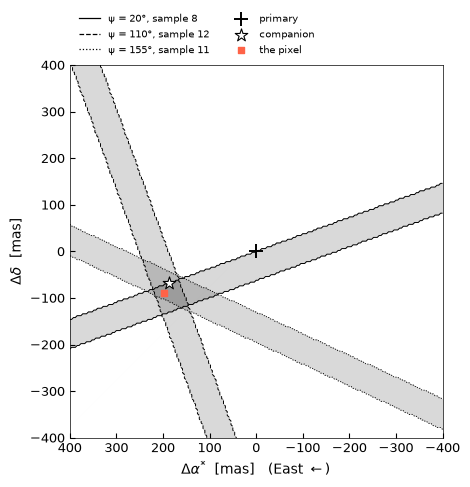

In [7]:
# The strips of three windows through one pixel near the companion.
pixel = theta + np.array([10.0, -20.0])                      # (dra*, ddec) of the pixel [mas]
three_angles = np.deg2rad([20.0, 110.0, 155.0])              # the scan angles of the three windows [rad]
fig, ax = plt.subplots(figsize=(4.8, 5.3))
for psi_j, line_style in zip(three_angles, ("-", "--", ":")):
    pixel_eta = ins.project_al(pixel[0], pixel[1], psi_j)    # Eq. 9: the pixel's along-scan coordinate [mas]
    k = int(np.floor((pixel_eta - grid[0]) / pitch + 0.5))           # the sample that covers the pixel
    # the mask of the sky pixels whose along-scan coordinate is within half a pitch of sample k's center: the strip
    inside = np.abs(sky_dra * np.sin(psi_j) + sky_ddec * np.cos(psi_j) - grid[k]) < pitch / 2
    strip = inside.astype(float)                             # 1 inside the strip, 0 outside, for the contours
    ax.contourf(sky_dra, sky_ddec, strip, levels=[0.5, 1.5], colors=["k"], alpha=0.15)
    ax.contour(sky_dra, sky_ddec, strip, levels=[0.5], colors="k", linewidths=0.7, linestyles=line_style)
    # an empty line: it draws nothing and gives the legend its entry
    ax.plot([], [], color="k", lw=0.9, ls=line_style, label=f"ψ = {np.degrees(psi_j):.0f}°, sample {k}")
ax.scatter(0, 0, **PRIMARY, label="primary")
companion_style = {**TRUTH, "s": 90}                         # the TRUTH table with a smaller star
ax.scatter(theta[0], theta[1], **companion_style, label="companion")
ax.scatter(pixel[0], pixel[1], marker="s", s=14, color=ACCENT, zorder=9, label="the pixel")
ax.set(xlim=(400, -400), ylim=(-400, 400), xlabel=EAST, ylabel=NORTH, aspect="equal")
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2)
plt.tight_layout()
plt.show()

## 2. The plain mean, and why it fails

*Paper: not in the paper; the plain mean is the stack without the weights of faststack, here to show what the weights are for.*

The simplest stack gives every pixel the mean of the samples that cover it.
Near the companion, most windows contribute its own light; but the window
whose scan runs along the line from the pixel to the primary contributes a
sample that holds the primary's light, five times brighter. One such sample
in 80 raises the mean by a sixteenth of the primary's peak; and every pixel on
every scan line through the primary gets one, so the primary is smeared
into a star of rays, exactly the halo of plain back-projection in tutorial
1, without the ramp filter to remove it.

In [8]:
# the noise-free windows of the pair on the 80 even directions: (80, 18), flux per sample
even_windows = windows_of(theta, EVEN)

In [9]:
# the footprint rule, written out: the sample of each window that covers each sky pixel
def collect(psi, windows, eta0=None):
    """The sample that each window contributes to each sky pixel of the page's grid (the rule of block 1).

    Inputs
        psi       the scan angles [rad], one per window
        windows   the windows, one row per window, flux per sample
        eta0      the windows' zero points [mas], one per window; None: all zero
    Returns
        values    one sky image per window: values[j] holds, at each pixel, the sample of window j that covers
                  it [flux per sample], and NaN where the pixel falls outside the window"""
    # step 0, the empty result: one image of NaN per window, on the page's sky grid
    values = np.full((psi.size,) + sky_dra.shape, np.nan)
    for j in range(psi.size):                                    # j counts the windows
        psi_j = psi[j]
        window = windows[j]
        # step 1, every pixel's along-scan coordinate in window j (Eq. 9), in the window's own frame
        eta = sky_dra * np.sin(psi_j) + sky_ddec * np.cos(psi_j)
        if eta0 is not None:
            eta = eta - eta0[j]
        # step 2, k: the number of the sample whose center is nearest to each pixel (the formula of block 1)
        k = np.floor((eta - grid[0]) / pitch + 0.5).astype(int)
        # step 3, the mask `inside` keeps the pixels that window j covers; k[inside] is the covering sample's
        # index there
        inside = (k >= 0) & (k < grid.size)
        values[j][inside] = window[k[inside]]
    return values

In [10]:
# the plain mean over the windows (axis 0) of the collected samples; nanmean omits the windows that do not
# cover a pixel
values = collect(EVEN, even_windows)
plain = np.nanmean(values, axis=0)

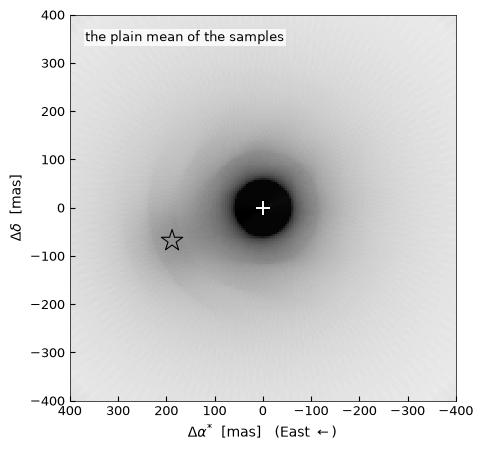

In [11]:
# Figure 2: the plain mean; the primary's rays cross the whole image
fig, ax = plt.subplots(figsize=(4.8, 4.6))
show(ax, plain, None, "the plain mean of the samples")
ax.set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 3. Harrison's four equations, for one pixel

*Paper: App. C.2 (faststack); the four equations are those of Harrison (2011), which the paper cites and does not write out.*

Sort the M samples a pixel collected, θ₁ ≤ … ≤ θ_M. The lowest few come
from the scans in which no bright star shared the pixel's strip, so their
mean is a first estimate of the pixel's own level:

$$r_0 = \frac{1}{m}\sum_{k \le m} \theta_k,\qquad m = \max(1, \lfloor \alpha M \rfloor) \quad\text{(Eq. 3)}$$

Every sample is then weighted

$$w_k = 1 \ (k \le \alpha M),\qquad w_k = \exp\!\left(1 - (\theta_k / r_0)^2\right)\ (k > \alpha M) \quad\text{(Eq. 2)}$$

so a sample far above the pixel's low level, one that holds another star's
light, hardly counts; and the pixel's value and spread are the weighted mean
and the weighted variance about it:

$$\hat\theta = \frac{\sum_k w_k \theta_k}{\sum_k w_k} \quad\text{(Eq. 1)},\qquad
\hat\sigma^2 = \frac{\sum_k w_k (\theta_k - \hat\theta)^2}{\sum_k w_k} \quad\text{(Eq. 4)}.$$

**The paper's parameters, and what they become here.** Harrison's method has
five inputs. The table lists each as the paper states it, and what it becomes
in this package's `scanlib.radon.faststack`: an argument of the function, a
constant that cancels, or something the toy windows do not have.

| in Harrison (2011) | in `radon.faststack` |
|---|---|
| the weighting parameter α, 0 < α < 1, "k ≤ αN_w" (the paper leaves αN_w < 1 undefined) | `alpha`, default 0.05; r₀ rests on m = max(1, ⌊αM⌋) samples |
| the footprint factor 1/n_sk, the number of image pixels a sample covers, which favors a compact sample (a 2-D sky-mapper pixel) over a long one (a 1-D astrometric-field sample) when both are stacked | canceled: all samples are of one kind and the toy windows have no across-scan extent, so n_sk is one constant in Eqs. 1, 3 and 4 |
| the sample's area: one pixel along the scan by the window's full width across it (12 pixels of 177 mas for a faint-star window); a sample contributes to a pixel whose center lies in that area | the strip [gₖ − p/2, gₖ + p/2) along the scan, unbounded across it; `eta0` moves the strips of each window to its own phase; the across-scan width, and the sources it censors, are not modeled (limitation notebook 1) |
| the reconstructed image's pixel grid | `half` and `step`, in mas |
| the 0.2″ disc masked around the primary in the paper's figures | a display choice; the arrays are complete (here `vmax`) |

Two more things differ in the data, not the method. Harrison's samples are
counts on a sky background, all positive; here the background is zero, so on
noise-free empty sky r₀ = 0 and the ratio is undefined (the package then
takes the smallest positive float for r₀, which suppresses every sample
above it), and with noise the lowest samples are the negative tail and r₀ is
negative (limitation notebook 6). And the paper's later step, faststack read
along a trial proper motion, is not in this package. The figure shows the
sorted samples of three pixels: at the companion, on the primary's scan
line through it, and on empty sky; the cell writes the equations out and
checks them against `radon.faststack`.

In [12]:
# Harrison's Eqs. 1-4 written out for one pixel; alpha is the trimming fraction
alpha = 0.05


def faststack_pixel(values_at_pixel, alpha=0.05):
    """Harrison's Eqs. 1-4 for one pixel: the robust average of the samples the pixel collected.

    Inputs
        values_at_pixel   the samples the pixel collected, one per window [flux per sample]; NaN is ignored
        alpha             the trimming fraction: the share of the lowest samples that set r0
    Returns five things
        sorted_samples    the M samples in ascending order [flux per sample]
        weights           the weight of each sorted sample (Eq. 2)
        r0                the reference level, the mean of the lowest m samples (Eq. 3) [flux per sample]
        mean              the weighted mean (Eq. 1): the pixel's value [flux per sample]
        variance          the weighted variance about the mean (Eq. 4) [flux per sample, squared]"""
    # step 1, sort the samples that are numbers. M is their count; m is the count of the lowest that set r0
    is_number = np.isfinite(values_at_pixel)
    sorted_samples = np.sort(values_at_pixel[is_number])
    M = sorted_samples.size
    m = max(1, int(np.floor(alpha * M)))

    # step 2, Eq. 3: r0 is the mean of the m lowest samples, sorted_samples[:m]. Where it is exactly zero the
    # smallest positive float takes its place, so that the ratio of Eq. 2 is defined
    r0 = sorted_samples[:m].mean()
    if r0 == 0.0:
        r0 = np.finfo(float).tiny

    # step 3, Eq. 2: the m lowest samples keep the weight 1; np.arange(M) < m marks them. Each other sample
    # gets exp(1 - (sample / r0)^2)
    is_lowest = np.arange(M) < m
    weights = np.where(is_lowest, 1.0, np.exp(1.0 - (sorted_samples / r0) ** 2))

    # step 4, Eq. 1 and Eq. 4: the weighted mean, and the weighted variance about it
    mean = np.sum(weights * sorted_samples) / np.sum(weights)
    variance = np.sum(weights * (sorted_samples - mean) ** 2) / np.sum(weights)
    return sorted_samples, weights, r0, mean, variance

In [13]:
# the package's stack of the same windows (the fourth return value, the axis, is dropped with `_`), and the
# three pixels to look at, as (dra*, ddec) [mas]
image, variance, n_used, _ = radon.faststack(EVEN, even_windows, inst, half, step, alpha=alpha)
# pixels: a table from a pixel's name to its (dra*, ddec) [mas]; pixels["at the companion"] is theta
pixels = {"at the companion": theta, "between the stars": theta / 2, "empty sky": np.array([250.0, -250.0])}

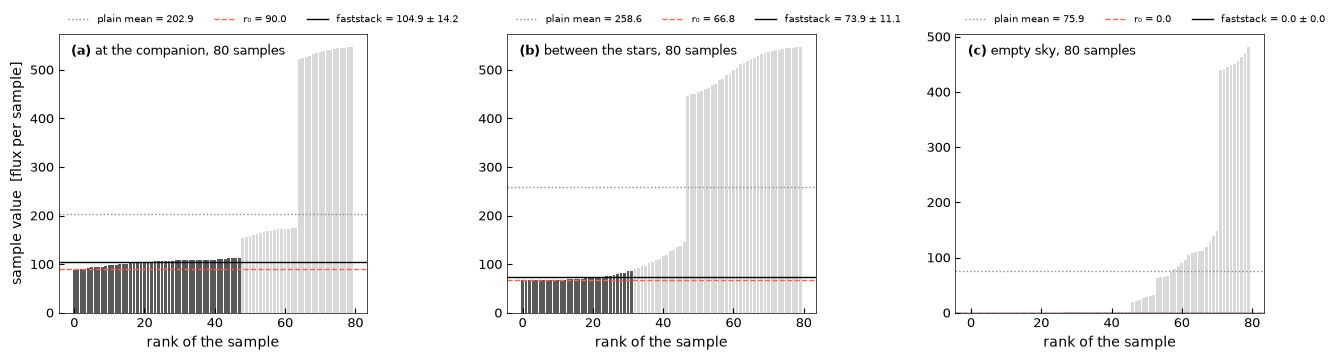

the written-out equations agree with faststack at the three pixels


In [14]:
# Figure 3: the sorted samples of each pixel, the plain mean, r0 and the stack's value; the assert checks the
# written-out equations against the package. (i, j) is the pixel's (row, column): the row from ddec, the
# column from dra*; values[:, i, j] is that pixel's sample from every window
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.7))
for ax, panel_letter, (name, (pixel_dra, pixel_ddec)) in zip(axes, "abc", pixels.items()):
    i = int(round((pixel_ddec + half) / step))                   # the pixel's row
    j = int(round((pixel_dra + half) / step))                    # the pixel's column
    sorted_samples, weights, r0, mean, var = faststack_pixel(values[:, i, j], alpha)
    assert np.isclose(mean, image[i, j]) and np.isclose(var, variance[i, j]) and sorted_samples.size == n_used[i, j]
    rank = np.arange(sorted_samples.size)                        # 0 for the lowest sample
    bar_colours = np.where(weights > 0.5, "0.35", "0.85")        # dark: the sample counts; light: all but removed
    ax.bar(rank, sorted_samples, color=bar_colours)
    plain_mean = sorted_samples.mean()
    ax.axhline(plain_mean, color="0.55", ls=":", lw=1, label=f"plain mean = {plain_mean:.1f}")
    ax.axhline(r0, color=ACCENT, ls="--", lw=1, label=f"r₀ = {r0:.1f}")
    ax.axhline(mean, color="k", lw=1, label=f"faststack = {mean:.1f} ± {np.sqrt(var):.1f}")
    letter(ax, panel_letter, f"{name}, {sorted_samples.size} samples")
    ax.set_xlabel("rank of the sample")
    ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=3)
axes[0].set_ylabel("sample value  [flux per sample]")
plt.tight_layout()
plt.show()
print("the written-out equations agree with faststack at the three pixels")

Light bars are the samples the weight all but removes; the dotted line is
the plain mean of all the samples, the dashed line r₀, the solid line the
faststack value. At the companion the
samples of most windows agree, and the few that also saw the primary are
dropped; between the stars the low samples set r₀ near zero and almost
everything is dropped; on empty sky every sample is near zero and the
estimate is zero. The plain mean would have been pulled up in all three.

## 4. The image, its variance, the sample count, and α

*Paper: App. C.2; Figs. C.1 and C.2 show faststack images.*

`radon.faststack` returns the image, the variance of Eq. 4, the number of samples
per pixel (NaN image and variance where it is zero), and the axis. The image
is in the windows' units, flux per sample, with no LSF taken out: a star
appears as a disc of the sample values it produced, a few pitches across
(the LSF spreads a star over about three samples, and the strips of all
directions through it fill a disc), not as a point. The trimming fraction α
sets how many of the lowest samples define r₀ (at 80 windows, α = 0.05
means four samples): too small, and r₀ rests on one sample, with its noise;
too large, and samples that hold another star's light enter r₀, so the
suppression weakens and the primary's disc grows. Harrison found the image
insensitive to α between 0.05 and 0.45 where the transits cover the
directions evenly, and sensitive to it where they do not, and recommends a
low value; limitation notebook 2 repeats that test on the Gaia forecast's
angles. Harrison's 0.05 is the default.

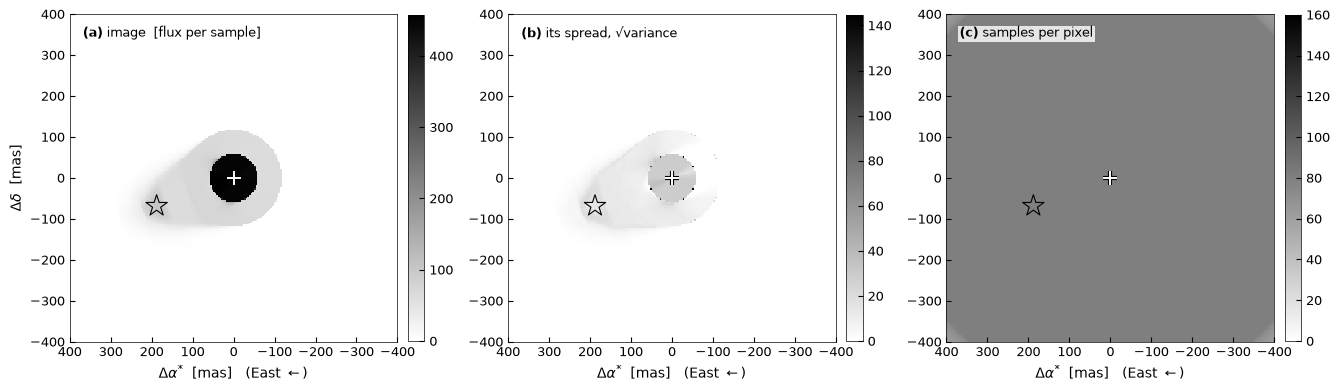

In [15]:
# Figure 4: the faststack image, its spread and the number of samples per pixel, on the even directions
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))
drawn = show(axes[0], image, "a", "image  [flux per sample]")
fig.colorbar(drawn, ax=axes[0], fraction=0.046, pad=0.03)
drawn = show(axes[1], np.sqrt(variance), "b", "its spread, √variance")
fig.colorbar(drawn, ax=axes[1], fraction=0.046, pad=0.03)
# the count is 80 almost everywhere: a scale from 0 to twice the number of windows shows it as mid-gray
drawn = show(axes[2], n_used, "c", "samples per pixel", vmax=2 * EVEN.size)
fig.colorbar(drawn, ax=axes[2], fraction=0.046, pad=0.03)
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

In [16]:
# the (row, column) of the pixel at the companion and of the pixel halfway between the stars:
# the row from ddec, the column from dra*
companion_row = int(round((theta[1] + half) / step))
companion_column = int(round((theta[0] + half) / step))
halfway_row = int(round((theta[1] / 2 + half) / step))
halfway_column = int(round((theta[0] / 2 + half) / step))

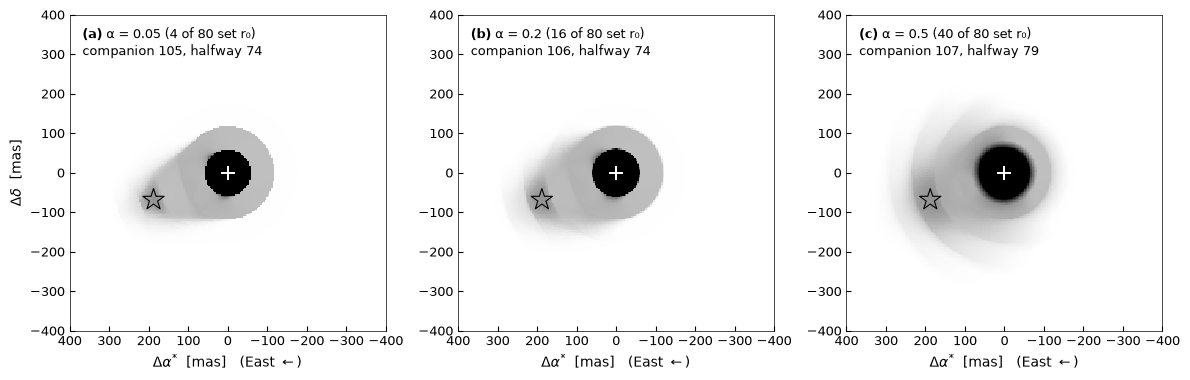

In [17]:
# Figure 5: the image at three trimming fractions; [0] keeps the image of the four return values
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, panel_letter, alpha_shown in zip(axes, "abc", (0.05, 0.2, 0.5)):
    stack = radon.faststack(EVEN, even_windows, inst, half, step, alpha=alpha_shown)[0]
    n_lowest = max(1, int(np.floor(alpha_shown * EVEN.size)))    # the m of Eq. 3: the samples that set r0
    at_companion = stack[companion_row, companion_column]
    at_halfway = stack[halfway_row, halfway_column]
    show(ax, stack, panel_letter,
         f"α = {alpha_shown} ({n_lowest} of 80 set r₀)\ncompanion {at_companion:.0f}, halfway {at_halfway:.0f}",
         vmin=0, vmax=250)
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 5. The sampling phase

*Paper: App. C.2, Fig. C.2 (one sampling phase: the steps and the plateau).*

faststack reads one sample per window, so where the samples fall matters.
With every window at the same phase (all zero points 0, as above) a pixel
takes one of a few sample values and the image is blocky; and two stars two
FWHM apart are joined by a plateau, because at every angle between them
some sample straddles both. Real windows fall wherever the detector's pixels
happen to be: each has its own zero point η₀, the sky coordinate of its
sample grid's origin, known and passed with the windows (`eta0=`). The cell
gives each window a zero point uniform within half a pitch, renders the
windows at those phases, and compares.

In [18]:
# each window gets its own zero point, uniform within half a pitch; the windows are rendered at those phases and
# stacked with them. [0] keeps the image of the four return values
# the seed is one number, 3: a label only (why 3: not stated). The generator's draws are the 80 zero points
rng_phase = np.random.default_rng(3)
eta0 = rng_phase.uniform(-0.5, 0.5, EVEN.size) * pitch        # the windows' zero points [mas]
own_phase_windows = windows_of(theta, EVEN, eta0=eta0)
own = radon.faststack(EVEN, own_phase_windows, inst, half, step, eta0=eta0)[0]

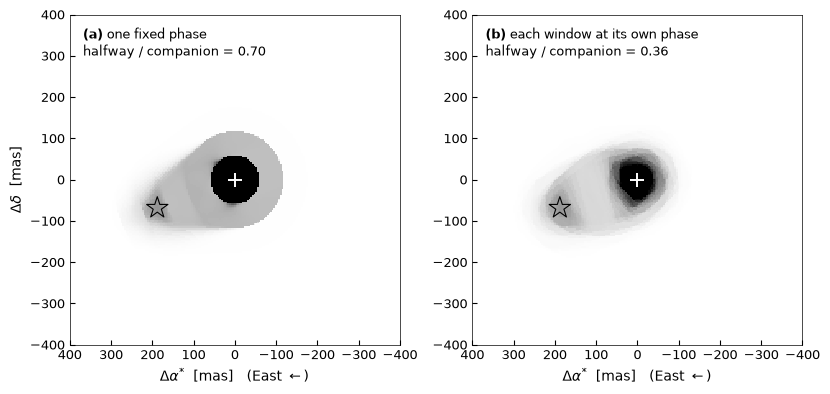

In [19]:
# Figure 6: one fixed phase, and each window at its own; the value halfway between the stars relative to the
# value at the companion
fig, axes = plt.subplots(1, 2, figsize=(8.4, 4.4))
# one row per panel: the panel, its letter, its image, its name
panels = ((axes[0], "a", image, "one fixed phase"),
          (axes[1], "b", own, "each window at its own phase"))
for ax, panel_letter, stack, name in panels:
    ratio = stack[halfway_row, halfway_column] / stack[companion_row, companion_column]
    show(ax, stack, panel_letter, f"{name}\nhalfway / companion = {ratio:.2f}", vmin=0, vmax=250)
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 6. Where the picture breaks

*Paper: App. C.2, Fig. C.1 (faststack on two scan laws); the close companion and the drifting companion are not in the paper for faststack, they are here because the stack assumes resolved, static sources.*

**Clumped scan directions.** With the Gaia forecast's 40 angles (tutorial 1,
section 4) the strips through a pixel come from a few bundles of directions.
The stars are no longer compact: each becomes the polygon its few strips cut
out, a pitch wide along each scanned direction, and the plateau between the
stars widens.

**A companion inside one FWHM.** At 80 mas the companion's samples are never
clear of the primary's: in every window the strip that covers the companion
also holds the primary's light. Its pixels have no low samples to set r₀
from, and it sits on the edge of the primary's core rather than in a peak of
its own. The LSF, which the stack ignores, sets this limit; the forward fit,
which models it, resolves such pairs (tutorial 0).

**A drifting companion.** As for the inverse Radon transform, the stack
assumes one static scene. A companion drifting 30 mas/yr over 4.6 years is
somewhere else in every window and is smeared along its track; where the
drift exceeds a FWHM its peak drops. faststack can be read along a trial
motion instead, the dynamical channel of Harrison's picture, which is not in
this package.

In [20]:
# the inputs of three pathological cases: the Gaia forecast's 40 angles, a companion at 80 mas, and a companion
# drifting 30 mas/yr (theta_moving: dra*, ddec, mu_a, mu_d) over the epochs tau [yr]
ref = np.load("../../tests/reference/reference_cases.npz")
GAIA = ref["static_pair/inputs/psi"]
close = 80.0 * np.array([np.sin(position_angle), np.cos(position_angle)])    # the close companion (dra*, ddec) [mas]
tau = np.linspace(-2.3, 2.3, EVEN.size)
theta_moving = np.array([theta[0], theta[1], 25.0, -16.6])

In [21]:
# the three stacks, each as (name, image, the sources to mark; None: the primary and the companion); [0] keeps
# the image of the four return values
forecast_windows = windows_of(theta, GAIA)
forecast_image = radon.faststack(GAIA, forecast_windows, inst, half, step)[0]
close_windows = windows_of(close, EVEN)
close_image = radon.faststack(EVEN, close_windows, inst, half, step)[0]
close_marks = np.vstack([[0.0, 0.0], close])                 # the primary's row, then the close companion's
drifting_windows = windows_of(theta_moving, EVEN, tau=tau)
drifting_image = radon.faststack(EVEN, drifting_windows, inst, half, step)[0]
cases = (
    ("Gaia forecast, 40 windows", forecast_image, None),
    ("companion at 80 mas (0.8 FWHM)", close_image, close_marks),
    ("companion drifting 30 mas/yr", drifting_image, None),
)

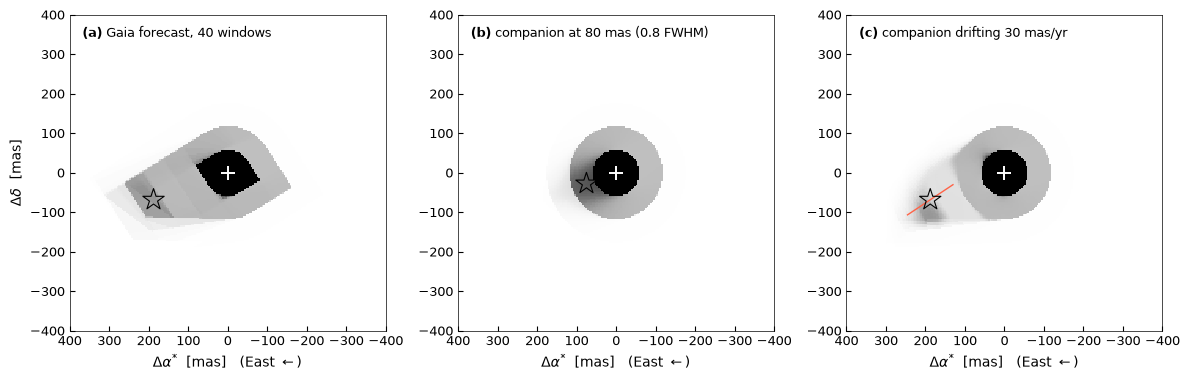

companion's level: static 105; drifting 47 flux per sample


In [22]:
# Figure 7: the three cases; in (c) the line is the companion's true track over the campaign.
# theta_moving[:2] is the position at the reference epoch, theta_moving[2:] the proper motion; np.outer makes
# each epoch times the proper motion: one row for the first epoch and one for the last
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, panel_letter, (title, stack, marks) in zip(axes, "abc", cases):
    show(ax, stack, panel_letter, title, marks=marks, vmin=0, vmax=250)
first_and_last = [tau.min(), tau.max()]
track = theta_moving[:2] + np.outer(first_and_last, theta_moving[2:])
axes[2].plot(track[:, 0], track[:, 1], color=ACCENT, lw=1)       # column 0 is dra*, column 1 is ddec
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()
static_level = image[companion_row, companion_column]
drifting_level = drifting_image[companion_row, companion_column]
print(f"companion's level: static {static_level:.0f}; drifting {drifting_level:.0f} flux per sample")

## What this establishes

- faststack reads, per pixel, one sample per window, sorts them, sets a
  reference level from the lowest few and weights the rest down by
  exp(1 − (θ/r₀)²): the samples that hold another star's light are dropped,
  and the primary's rays, which the plain mean and the plain back-projection
  smear across the sky, are gone.
- The image is in flux per sample with no LSF removed; its stars are a
  pitch wide, and at one fixed phase it is blocky and joins stars within two
  FWHM by a plateau, which windows at their own phases mostly remove.
- Clumped directions turn the stars into polygons, a companion inside one
  FWHM never leaves the primary's core, and a drifting companion is smeared.
  It is a detector's picture, robust and model-free, and nothing is
  measured on it: positions, fluxes and motions come from the forward fit
  (`scanlib.joint`).

## What is next

[The triangulation map](03_triangulation_map.ipynb): the third picture, made from positions measured in each window and not from the samples.